# 22 — Week 6: noise (inference only) and the ablation table, validation

The trained models are NOT retrained: the circuits of the trained hybrid QNNs (`model.pt`) and the fixed QRC reservoirs
with their trained ridge readouts are evaluated with noise on the validation split (inference-only protocol, as in
the QRC template). Code: `NoisyQuantumBlock` / `noisy_copy` in `src/models/quantum.py`, `quantum_features_noisy` in
`src/models/qrc.py`.

Noise model (approximate, provisional): single-qubit depolarizing p1 after every rotation; for every two-qubit gate a
single-qubit depolarizing channel p2 on both qubits; symmetric readout flip p_ro applied analytically; finite shots
(1,024). Settings: shots only; four depolarizing levels (p1 / p2 = 1e-4 / 1e-3 up to 1e-2 / 1e-1); two hardware-like
points with the published median two-qubit and readout errors of IBM Heron devices (ibm_marrakesh, Heron r2: CZ 3e-3,
readout 1.25e-2; ibm_torino, Heron r1: CZ 4e-3, readout 2.41e-2; arXiv 2607.11637, Table 4), with p1 = p2 / 10 assumed
(single-qubit errors not reported there) and 1,024 shots. A depolarizing probability is not identical to a reported
gate error; the points indicate the order of magnitude only.

Scope: hybrid QNN (main configuration, 3 seeds; its no-entanglement variant, seed 0) and the 4-qubit QRC (3 reservoirs,
plus its no-entanglement variant) with density-matrix simulation. The main 8-qubit QRC gets shots and readout noise
only: an 8-qubit density-matrix simulation of every validation minute takes hours per setting on a laptop.
Cell 6 adds a noise-aware readout for QRC (readout refitted on noisy reservoir states, the realistic hardware workflow
for reservoir computing). Results are appended to CSV files row by row; the notebook is resumable. **The test split is
not used.**

In [1]:
# Cell 1: setup
import sys, json, time, math, warnings, traceback
from pathlib import Path
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from models import rnn as R
from models import quantum as Q
from models import qrc as QR
from evaluation import metrics as M

REP5, REP = ROOT / "reports" / "week5", ROOT / "reports" / "week6"
FIG = ROOT / "reports" / "figures" / "week6"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
qv = json.loads((REP5 / "qnn_val.json").read_text())
qr = json.loads((REP5 / "qrc_val.json").read_text())
MAIN, QNN_GROUP = qv["main_hybrid"], qv.get("group", "week5_qnn")
QRC_GROUP, QRC_N, QRC_DEPTH = "week5_qrc", int(qr["n_qubits"]), int(qr["depth"])
BEST_SCALE = {k: float(v) for k, v in qr["best_scale"].items()}
SEEDS = [0, 1, 2]
SETTINGS = [("exact", {}), ("shots 1024", {"shots": 1024}),
            ("depol 1e-4 / 1e-3", {"p1": 1e-4, "p2": 1e-3}), ("depol 1e-3 / 1e-2", {"p1": 1e-3, "p2": 1e-2}),
            ("depol 3e-3 / 3e-2", {"p1": 3e-3, "p2": 3e-2}), ("depol 1e-2 / 1e-1", {"p1": 1e-2, "p2": 1e-1}),
            ("Heron r2-like (marrakesh)", {"p1": 3e-4, "p2": 3e-3, "p_ro": 1.25e-2, "shots": 1024}),
            ("Heron r1-like (torino)", {"p1": 4e-4, "p2": 4e-3, "p_ro": 2.41e-2, "shots": 1024})]
HQ = Q.variant_name(MAIN)
HQ_NOENT = Q.variant_name({**MAIN, "entangle": False})
DATA_CFG = {"scaling": "local", "calendar": False, "covariates": False}
SUMMARY = {"settings": SETTINGS, "main_hybrid": HQ}
print("hybrid:", HQ, "/", HQ_NOENT, "| QRC main n =", QRC_N, "| noisy QRC at n = 4 | settings:", [s for s, _ in SETTINGS])

hybrid: hqnn_noreup_q4_l2 / hqnn_noent_noreup_q4_l2 | QRC main n = 8 | noisy QRC at n = 4 | settings: ['exact', 'shots 1024', 'depol 1e-4 / 1e-3', 'depol 1e-3 / 1e-2', 'depol 3e-3 / 3e-2', 'depol 1e-2 / 1e-1', 'Heron r2-like (marrakesh)', 'Heron r1-like (torino)']


In [2]:
# Cell 2: unit checks of the noise code (no real data)
checks = {}
torch.manual_seed(0)
m, _ = Q.build({**MAIN, "n_qubits": 4}, R.INPUT_LEN)
x = torch.randn(200, R.INPUT_LEN, 1)
with torch.no_grad():
    y0 = m(x)
    d0 = float((Q.noisy_copy(m)(x) - y0).abs().max())
    d1 = float((Q.noisy_copy(m, p1=1e-7, p2=1e-7)(x) - y0).abs().max())
    d2 = float((Q.noisy_copy(m, p1=1e-2, p2=1e-1)(x) - y0).abs().max())
    z = m.middle(m.angles(x))
    zr = Q.noisy_copy(m, p_ro=0.1).middle(m.angles(x))
checks["no_noise_equals_exact"] = d0 < 1e-5
checks["tiny_noise_close_to_exact"] = d1 < 1e-3
checks["strong_noise_changes_output"] = d2 > 1e-3
checks["readout_flip_scales_Z"] = float((zr - 0.8 * z).abs().max()) < 1e-5
U = np.tanh(np.random.default_rng(0).normal(size=(64, 4)))
F0 = QR.quantum_features(U, depth=QRC_DEPTH, scale=0.8, seed=1)
Fn = QR.quantum_features_noisy(U, depth=QRC_DEPTH, scale=0.8, seed=1)
Fs = np.mean([QR.quantum_features_noisy(U, depth=QRC_DEPTH, scale=0.8, seed=1, shots=1024, rng_seed=s) for s in range(20)], 0)
checks["qrc_no_noise_equals_exact"] = float(np.abs(Fn - F0).max()) < 1e-6
checks["qrc_shots_unbiased"] = float(np.abs(Fs - F0).mean()) < 0.01
print(f"hybrid: |noisy(p=0) - exact| {d0:.1e} | p=1e-7: {d1:.1e} | p1/p2=1e-2/1e-1: {d2:.3f} | QRC mean |avg of 20 shot "
      f"runs - exact| {float(np.abs(Fs - F0).mean()):.4f}")
NOISE_OK = all(checks.values())
print(checks, "\nUNIT CHECKS PASSED" if NOISE_OK else "\nUNIT CHECKS FAILED: send this output")

hybrid: |noisy(p=0) - exact| 1.2e-07 | p=1e-7: 6.3e-07 | p1/p2=1e-2/1e-1: 0.225 | QRC mean |avg of 20 shot runs - exact| 0.0054
{'no_noise_equals_exact': True, 'tiny_noise_close_to_exact': True, 'strong_noise_changes_output': True, 'readout_flip_scales_Z': True, 'qrc_no_noise_equals_exact': True, 'qrc_shots_unbiased': True} 
UNIT CHECKS PASSED


In [3]:
# Cell 3: real data; reload the trained hybrid models and check that the exact simulation reproduces the stored
# validation forecasts (the inference-only protocol must start from exactly the trained models)
assert NOISE_OK, "run cell 2 first"
md = pl.read_parquet(ROOT / "data" / "processed" / "model_dataset.parquet")
meta = json.loads((ROOT / "data" / "processed" / "model_dataset_meta.json").read_text())
data = R.Data(md, DATA_CFG)
va = data.origins("val")
L24 = md["L24_kW"].to_numpy().astype(float)
mod5 = md["mod5"].to_numpy().astype(int)

def score(preds):
    out = {}
    for h in R.HORIZONS:
        t = data.idx[h]["val"]
        r = M.evaluate(data.P[t + h], preds[h], data.P[t], l24=L24[t], ramp=md[f"ramp_h{h}"].to_numpy().astype(float)[t],
                       thr=meta["thresholds"][str(h)]["rel_p95"], mod5_target=mod5[t + h] if h == 1 else None)
        out[h] = r
    return out

MODELS = {}
rep = []
for name, seeds in ((HQ, SEEDS), (HQ_NOENT, [0])):
    for s in seeds:
        d = ROOT / "experiments" / QNN_GROUP / f"{name}_s{s}"
        model, cfg = Q.load_trained(d, data)
        MODELS[(name, s)] = model
        pv = Q.predict(model, data, va)
        st = pl.read_parquet(d / "predictions_val.parquet")
        diff = max(float(np.abs(pv[np.searchsorted(va, data.idx[h]["val"]), j] -
                                st.filter(pl.col("h") == h).sort("minute_epoch")["yhat"].to_numpy()).max())
                   for j, h in enumerate(R.HORIZONS))
        rep.append({"model": name, "seed": s, "max_abs_diff_kW": diff, "ok": diff < 1e-3})
rep = pl.DataFrame(rep)
print(rep)
assert rep["ok"].all(), "the reloaded models do not reproduce the stored validation forecasts: send this output"
print("REPRODUCTION PASSED")

shape: (4, 4)
┌─────────────────────────┬──────┬─────────────────┬──────┐
│ model                   ┆ seed ┆ max_abs_diff_kW ┆ ok   │
│ ---                     ┆ ---  ┆ ---             ┆ ---  │
│ str                     ┆ i64  ┆ f64             ┆ bool │
╞═════════════════════════╪══════╪═════════════════╪══════╡
│ hqnn_noreup_q4_l2       ┆ 0    ┆ 0.0             ┆ true │
│ hqnn_noreup_q4_l2       ┆ 1    ┆ 0.0             ┆ true │
│ hqnn_noreup_q4_l2       ┆ 2    ┆ 0.0             ┆ true │
│ hqnn_noent_noreup_q4_l2 ┆ 0    ┆ 0.0             ┆ true │
└─────────────────────────┴──────┴─────────────────┴──────┘
REPRODUCTION PASSED


In [4]:
# Cell 4: HYBRID QNN under noise (validation). Resumable: rows already in the CSV are skipped.
OUT_H = REP / "noise_hybrid_val.csv"
done_keys = set()
if OUT_H.exists():
    old = pl.read_csv(OUT_H)
    done_keys = set(zip(old["model"], old["seed"], old["setting"]))
T = time.time()
for (name, s), model in MODELS.items():
    for label, kw in SETTINGS:
        if (name, s, label) in done_keys:
            continue
        if name == HQ_NOENT and label.startswith(("depol 1e-4", "depol 3e-3")):
            continue                                  # no-entanglement variant: a reduced set of settings
        t0 = time.time()
        mn = Q.noisy_copy(model, seed=1000 + s, **kw) if kw else model
        pv = Q.predict(mn, data, va, batch=2048)
        res = score({h: pv[np.searchsorted(va, data.idx[h]["val"]), j] for j, h in enumerate(R.HORIZONS)})
        row = {"model": name, "seed": s, "setting": label, **{k: kw.get(k, 0) or 0 for k in ("p1", "p2", "p_ro", "shots")},
               **{f"MAE_h{h}": res[h]["MAE"] for h in R.HORIZONS}, **{f"skill_h{h}": res[h]["skill_MAE"] for h in R.HORIZONS},
               "s": round(time.time() - t0, 1)}
        pl.concat([pl.read_csv(OUT_H), pl.DataFrame([row])], how="diagonal_relaxed").write_csv(OUT_H) if OUT_H.exists() \
            else pl.DataFrame([row]).write_csv(OUT_H)
        Q.log_variant(ROOT, {"stage": "noise", "group": QNN_GROUP, "variant": name, "seed": s, "setting": label,
                             **{f"val_skill_h{h}": round(res[h]["skill_MAE"], 4) for h in R.HORIZONS}})
        print(f"[{time.strftime('%H:%M:%S')}] {name}_s{s} | {label:28s} | skill " +
              " / ".join(f"{res[h]['skill_MAE']:+.3f}" for h in R.HORIZONS) + f" | {time.time() - t0:.0f} s")
print(f"hybrid noise runs handled in {(time.time() - T) / 60:.1f} min")

[10:39:00] hqnn_noreup_q4_l2_s0 | exact                        | skill +0.059 / +0.057 / +0.046 | 0 s
[10:39:04] hqnn_noreup_q4_l2_s0 | shots 1024                   | skill +0.045 / +0.051 / +0.043 | 3 s
[10:39:28] hqnn_noreup_q4_l2_s0 | depol 1e-4 / 1e-3            | skill +0.059 / +0.057 / +0.046 | 25 s
[10:39:52] hqnn_noreup_q4_l2_s0 | depol 1e-3 / 1e-2            | skill +0.061 / +0.057 / +0.045 | 24 s
[10:40:16] hqnn_noreup_q4_l2_s0 | depol 3e-3 / 3e-2            | skill +0.061 / +0.053 / +0.040 | 24 s
[10:40:40] hqnn_noreup_q4_l2_s0 | depol 1e-2 / 1e-1            | skill +0.040 / +0.024 / +0.016 | 24 s
[10:41:07] hqnn_noreup_q4_l2_s0 | Heron r2-like (marrakesh)    | skill +0.047 / +0.051 / +0.042 | 27 s
[10:41:34] hqnn_noreup_q4_l2_s0 | Heron r1-like (torino)       | skill +0.048 / +0.052 / +0.042 | 27 s
[10:41:34] hqnn_noreup_q4_l2_s1 | exact                        | skill +0.084 / +0.056 / +0.042 | 0 s
[10:41:37] hqnn_noreup_q4_l2_s1 | shots 1024                   | skill +0.08

In [5]:
# Cell 5: QRC under noise. (a) 4-qubit QRC and its no-entanglement variant (density matrix; 3 reservoirs);
# (b) the main 8-qubit QRC: shots and readout noise only (cached exact reservoir states). Resumable.
OUT_Q = REP / "noise_qrc_val.csv"
done_keys = set()
if OUT_Q.exists():
    old = pl.read_csv(OUT_Q)
    done_keys = set(zip(old["model"], old["seed"], old["setting"]))
lo, hi = int(va.min()) - (R.INPUT_LEN - 1), int(va.max())
def add_row(row):
    pl.concat([pl.read_csv(OUT_Q), pl.DataFrame([row])], how="diagonal_relaxed").write_csv(OUT_Q) if OUT_Q.exists() \
        else pl.DataFrame([row]).write_csv(OUT_Q)
T = time.time()
for n, kinds, settings in ((4, ("qrc", "qrc_noent"), SETTINGS),
                           (QRC_N, ("qrc",), [s for s in SETTINGS if "depol" not in s[0] and "Heron" not in s[0]] +
                            [("readout 1.25e-2 + shots", {"p_ro": 1.25e-2, "shots": 1024}),
                             ("readout 2.41e-2 + shots", {"p_ro": 2.41e-2, "shots": 1024})])):
    Un = QR.minute_inputs(data, md, n)
    for k in kinds:
        base = QR.variant_name(k, n, QRC_DEPTH)
        for s in SEEDS:
            run = ROOT / "experiments" / QRC_GROUP / f"{base}_{QR.scale_tag(BEST_SCALE[k])}_s{s}"
            if not (run / "readout.npz").exists():
                print("missing (run notebook 21 cell 5 first):", run.name)
                continue
            fits = QR.load_readout(run / "readout.npz")
            for label, kw in settings:
                if (base, s, label) in done_keys:
                    continue
                t0 = time.time()
                if kw.get("p1") or kw.get("p2"):
                    Phi = np.zeros((len(Un), QR.n_features("qrc", n)), dtype=np.float32)
                    Phi[lo:hi + 1] = QR.quantum_features_noisy(Un[lo:hi + 1], QRC_DEPTH, BEST_SCALE[k], s,
                                                               entangle=(k == "qrc"), rng_seed=1000 + s, **kw)
                else:
                    Phi = QR.reservoir_cached(ROOT / "experiments" / "_cache_qrc", k, Un, QRC_DEPTH, BEST_SCALE[k], s).copy()
                    if kw:
                        f1 = 1.0 - 2.0 * kw.get("p_ro", 0.0)
                        Phi[:, :3 * n] *= f1
                        Phi[:, 3 * n:] *= f1 ** 2
                        if kw.get("shots"):
                            rng = np.random.default_rng(1000 + s)
                            part = Phi[lo:hi + 1].astype(np.float64)
                            Phi[lo:hi + 1] = (2.0 * rng.binomial(kw["shots"], np.clip((1 + part) / 2, 0, 1)) / kw["shots"] - 1.0)
                preds = QR.predict_split(fits, Phi, data, "val")
                res = score(preds)
                add_row({"model": base, "seed": s, "setting": label, **{kk: kw.get(kk, 0) or 0 for kk in ("p1", "p2", "p_ro", "shots")},
                         **{f"MAE_h{h}": res[h]["MAE"] for h in R.HORIZONS}, **{f"skill_h{h}": res[h]["skill_MAE"] for h in R.HORIZONS},
                         "s": round(time.time() - t0, 1)})
                print(f"[{time.strftime('%H:%M:%S')}] {base}_s{s} | {label:28s} | skill " +
                      " / ".join(f"{res[h]['skill_MAE']:+.3f}" for h in R.HORIZONS) + f" | {time.time() - t0:.0f} s")
print(f"QRC noise runs handled in {(time.time() - T) / 60:.1f} min")

[10:47:38] qrc_q4_d4_s0 | exact                        | skill +0.064 / +0.041 / +0.031 | 4 s
[10:47:39] qrc_q4_d4_s0 | shots 1024                   | skill -28.908 / -151.735 / -79.854 | 1 s
[10:48:20] qrc_q4_d4_s0 | depol 1e-4 / 1e-3            | skill -0.608 / -5.104 / -2.165 | 42 s
[10:49:02] qrc_q4_d4_s0 | depol 1e-3 / 1e-2            | skill -11.719 / -53.029 / -22.891 | 42 s
[10:49:44] qrc_q4_d4_s0 | depol 3e-3 / 3e-2            | skill -36.649 / -122.603 / -32.695 | 42 s
[10:50:26] qrc_q4_d4_s0 | depol 1e-2 / 1e-1            | skill -117.523 / -80.803 / -189.318 | 42 s
[10:51:07] qrc_q4_d4_s0 | Heron r2-like (marrakesh)    | skill -30.107 / -156.000 / -90.652 | 41 s
[10:51:49] qrc_q4_d4_s0 | Heron r1-like (torino)       | skill -31.611 / -166.652 / -115.441 | 42 s
[10:51:53] qrc_q4_d4_s1 | exact                        | skill +0.064 / +0.041 / +0.032 | 4 s
[10:51:54] qrc_q4_d4_s1 | shots 1024                   | skill -90.484 / -240.180 / -55.066 | 1 s
[10:52:36] qrc_q4_d4_s1 |

In [6]:
# Cell 6: QRC with a NOISE-AWARE readout. With inference-only noise the readout was trained on exact reservoir
# states; on hardware it would be trained on the noisy states themselves. Here the ridge readout is refitted on noisy
# states of every minute (penalty chosen on noisy validation states, as in notebook 19): 8-qubit QRC with 1,024 shots
# (3 reservoirs, cheap), and 4-qubit QRC with Heron r2-like noise (density matrix for all ~300k minutes:
# ~10-25 min per reservoir, so NA_SEEDS = [0] by default; provisional). Resumable.
NA_SEEDS = [0]
T = time.time()
for n, k, label, kw, seeds in ((QRC_N, "qrc", "shots 1024 (noise-aware readout)", {"shots": 1024}, SEEDS),
                               (4, "qrc", "Heron r2-like (noise-aware readout)", dict(SETTINGS)["Heron r2-like (marrakesh)"], NA_SEEDS)):
    Un = QR.minute_inputs(data, md, n)
    base = QR.variant_name(k, n, QRC_DEPTH)
    for s in seeds:
        if (base, s, label) in done_keys:
            continue
        t0 = time.time()
        if kw.get("p1") or kw.get("p2"):
            Phi = QR.quantum_features_noisy(Un, QRC_DEPTH, BEST_SCALE[k], s, entangle=True, rng_seed=2000 + s, batch=1024,
                                            log=print, **kw)
        else:
            Phi = QR.reservoir_cached(ROOT / "experiments" / "_cache_qrc", k, Un, QRC_DEPTH, BEST_SCALE[k], s).astype(np.float64)
            rng = np.random.default_rng(2000 + s)
            Phi = (2.0 * rng.binomial(kw["shots"], np.clip((1 + Phi) / 2, 0, 1)) / kw["shots"] - 1.0).astype(np.float32)
        info, preds, fits, _ = QR.run_variant(data, md, Un, k, BEST_SCALE[k], s, depth=QRC_DEPTH, Phi=Phi)
        res = score(preds)
        add_row({"model": base, "seed": s, "setting": label, **{kk: kw.get(kk, 0) or 0 for kk in ("p1", "p2", "p_ro", "shots")},
                 **{f"MAE_h{h}": res[h]["MAE"] for h in R.HORIZONS}, **{f"skill_h{h}": res[h]["skill_MAE"] for h in R.HORIZONS},
                 "s": round(time.time() - t0, 1)})
        print(f"[{time.strftime('%H:%M:%S')}] {base}_s{s} | {label:36s} | skill " +
              " / ".join(f"{res[h]['skill_MAE']:+.3f}" for h in R.HORIZONS) + f" | {time.time() - t0:.0f} s")
print(f"noise-aware readout runs handled in {(time.time() - T) / 60:.1f} min")

[12:32:58] qrc_q8_d4_s0 | shots 1024 (noise-aware readout)     | skill +0.015 / +0.009 / +0.007 | 5 s
[12:33:03] qrc_q8_d4_s1 | shots 1024 (noise-aware readout)     | skill +0.018 / +0.007 / +0.005 | 5 s
[12:33:07] qrc_q8_d4_s2 | shots 1024 (noise-aware readout)     | skill +0.024 / +0.012 / +0.008 | 5 s
    noisy reservoir rows 1,024/303,840 | 1 s
    noisy reservoir rows 21,504/303,840 | 20 s
    noisy reservoir rows 41,984/303,840 | 38 s
    noisy reservoir rows 62,464/303,840 | 56 s
    noisy reservoir rows 82,944/303,840 | 75 s
    noisy reservoir rows 103,424/303,840 | 94 s
    noisy reservoir rows 123,904/303,840 | 112 s
    noisy reservoir rows 144,384/303,840 | 130 s
    noisy reservoir rows 164,864/303,840 | 148 s
    noisy reservoir rows 185,344/303,840 | 166 s
    noisy reservoir rows 205,824/303,840 | 184 s
    noisy reservoir rows 226,304/303,840 | 202 s
    noisy reservoir rows 246,784/303,840 | 222 s
    noisy reservoir rows 267,264/303,840 | 241 s
    noisy reservoir r

shape: (36, 10)
┌────────────┬─────────────────────────┬─────────────────────────────────┬─────────┬───┬───────────┬─────────┬─────────┬─────────┐
│ family     ┆ model                   ┆ setting                         ┆ n_seeds ┆ … ┆ skill_h15 ┆ sd_h1   ┆ sd_h5   ┆ sd_h15  │
│ ---        ┆ ---                     ┆ ---                             ┆ ---     ┆   ┆ ---       ┆ ---     ┆ ---     ┆ ---     │
│ str        ┆ str                     ┆ str                             ┆ u32     ┆   ┆ f64       ┆ f64     ┆ f64     ┆ f64     │
╞════════════╪═════════════════════════╪═════════════════════════════════╪═════════╪═══╪═══════════╪═════════╪═════════╪═════════╡
│ QRC        ┆ qrc_noent_q4_d4         ┆ exact                           ┆ 3       ┆ … ┆ 0.029     ┆ 0.0     ┆ 0.001   ┆ 0.001   │
│ QRC        ┆ qrc_noent_q4_d4         ┆ shots 1024                      ┆ 3       ┆ … ┆ -57.213   ┆ 22.255  ┆ 53.722  ┆ 56.609  │
│ QRC        ┆ qrc_noent_q4_d4         ┆ depol 1e-4 / 1e-3         

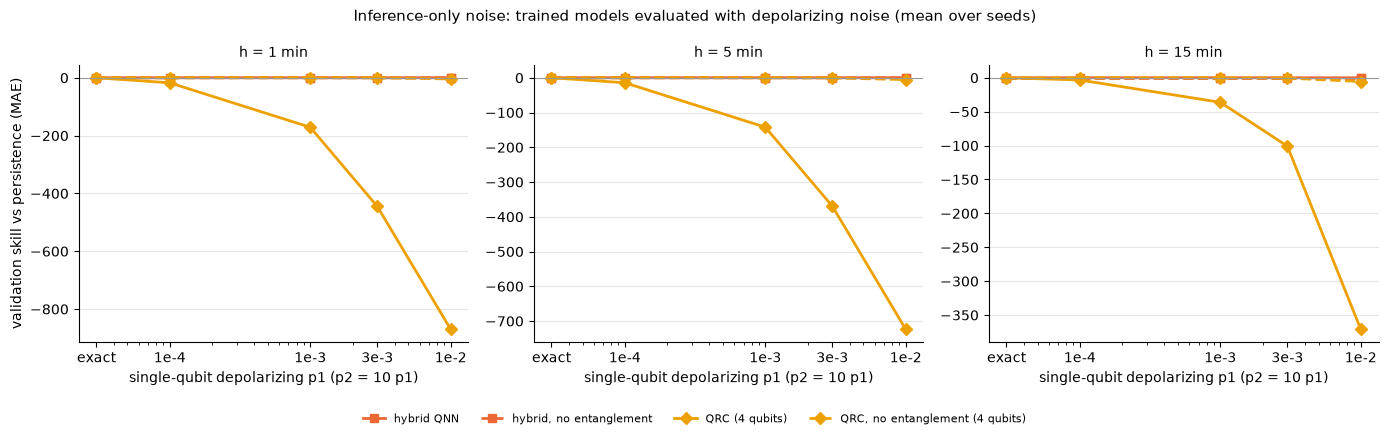

In [7]:
# Cell 7: noise table (mean +- sd over seeds) and figure
nz = pl.concat([pl.read_csv(OUT_H).with_columns(pl.lit("hybrid QNN").alias("family")),
                pl.read_csv(OUT_Q).with_columns(pl.lit("QRC").alias("family"))], how="diagonal_relaxed")
order = {lab: i for i, (lab, _) in enumerate(SETTINGS)}
order.update({"readout 1.25e-2 + shots": 50, "readout 2.41e-2 + shots": 51, "shots 1024 (noise-aware readout)": 60,
              "Heron r2-like (noise-aware readout)": 61})
nzs = (nz.group_by("family", "model", "setting").agg(pl.len().alias("n_seeds"),
        *[pl.col(f"skill_h{h}").mean().alias(f"skill_h{h}") for h in R.HORIZONS],
        *[pl.col(f"skill_h{h}").std().alias(f"sd_h{h}") for h in R.HORIZONS], pl.col("p1").first(), pl.col("p2").first())
        .with_columns(pl.col("setting").replace_strict(order, default=99).alias("_o")).sort("family", "model", "_o").drop("_o"))
nzs.write_csv(REP / "noise_summary_val.csv")
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(220)
print(nzs.select("family", "model", "setting", "n_seeds", *[pl.col(f"skill_h{h}").round(3) for h in R.HORIZONS],
                 *[pl.col(f"sd_h{h}").round(3) for h in R.HORIZONS]))

STY = {HQ: ("#eb6834", "s", "-", "hybrid QNN"), HQ_NOENT: ("#eb6834", "s", "--", "hybrid, no entanglement"),
       QR.variant_name("qrc", 4, QRC_DEPTH): ("#eda100", "D", "-", "QRC (4 qubits)"),
       QR.variant_name("qrc_noent", 4, QRC_DEPTH): ("#eda100", "D", "--", "QRC, no entanglement (4 qubits)")}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, h in zip(axes, R.HORIZONS):
    for mname, (c, mk, ls, lab) in STY.items():
        s = nzs.filter((pl.col("model") == mname) & pl.col("setting").str.starts_with("depol")).sort("p1")
        ex = nzs.filter((pl.col("model") == mname) & (pl.col("setting") == "exact"))
        if not s.height or not ex.height:
            continue
        x = np.concatenate([[3e-5], s["p1"].to_numpy()])
        y = np.concatenate([[ex[f"skill_h{h}"][0]], s[f"skill_h{h}"].to_numpy()])
        ax.plot(x, y, color=c, marker=mk, ls=ls, lw=2, ms=6, label=lab)
    ax.set_xscale("log"); ax.set_xticks([3e-5, 1e-4, 1e-3, 3e-3, 1e-2]); ax.set_xticklabels(["exact", "1e-4", "1e-3", "3e-3", "1e-2"])
    ax.axhline(0, color="#999999", lw=0.8)
    ax.set_title(f"h = {h} min", fontsize=10); ax.set_xlabel("single-qubit depolarizing p1 (p2 = 10 p1)")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0].set_ylabel("validation skill vs persistence (MAE)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=8, loc="lower center", ncol=4)
fig.suptitle("Inference-only noise: trained models evaluated with depolarizing noise (mean over seeds)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "D_noise_val.png", dpi=150); plt.show()
SUMMARY["noise"] = nzs.to_dicts()

In [8]:
# Cell 8: ABLATION TABLE (validation skill, mean +- sd over seeds): what each component contributes
rows = []
def add(block, label, model, src, h_vals):
    rows.append({"block": block, "variant": label, "model": model, "source": src, **h_vals})
qs = pl.read_csv(REP5 / "qnn_val_summary.csv")
for model, label in ((HQ, "hybrid QNN (main)"), (HQ_NOENT, "  without entangling gates"),
                     (Q.variant_name({**MAIN, "middle": "mlp"}), "  circuit -> matched classical MLP"),
                     (Q.variant_name({**MAIN, "middle": "bottleneck"}), "  no middle block (cos of angles)")):
    s = qs.filter(pl.col("model") == model)
    add("hybrid QNN", label, model, "nb 18", {f"skill_h{h}": s.filter(pl.col("h") == h)["skill_MAE"][0] if s.filter(pl.col("h") == h).height else None for h in R.HORIZONS})
scr = REP5 / "qnn_design_screen_s0.csv"
if scr.exists():
    for r_ in pl.read_csv(scr).iter_rows(named=True):
        add("hybrid design screen (seed 0)", f"  layers {r_['n_layers']}, re-uploading {r_['reupload']}", r_["variant"], "nb 18",
            {f"skill_h{h}": r_[f"skill_h{h}"] for h in R.HORIZONS})
qs2 = pl.read_csv(REP5 / "qrc_val_summary.csv")
for k, label in (("qrc", "QRC (main)"), ("qrc_noent", "  without entangling gates"), ("rf", "  quantum reservoir -> classical random features"),
                 ("raw", "  no reservoir (raw inputs)")):
    model = QR.variant_name(k, QRC_N, QRC_DEPTH)
    s = qs2.filter(pl.col("model") == model)
    add("QRC", label, model, "nb 19", {f"skill_h{h}": s.filter(pl.col("h") == h)["skill_MAE"][0] if s.filter(pl.col("h") == h).height else None for h in R.HORIZONS})
for r_ in nzs.filter(pl.col("setting").is_in(["exact", "shots 1024", "Heron r2-like (marrakesh)", "Heron r1-like (torino)"])
                     | pl.col("setting").str.contains("noise-aware")).iter_rows(named=True):
    add("noise", f"  {r_['setting']}", r_["model"], "nb 22", {f"skill_h{h}": r_[f"skill_h{h}"] for h in R.HORIZONS})
abl = pl.DataFrame(rows, infer_schema_length=None)
abl.write_csv(REP / "ablation_noise_table_val.csv")
print(abl.with_columns([pl.col(f"skill_h{h}").round(3) for h in R.HORIZONS]))
SUMMARY["ablation"] = abl.to_dicts()

shape: (32, 7)
┌───────────────────────────────┬─────────────────────────────────┬─────────────────────────┬────────┬──────────┬──────────┬───────────┐
│ block                         ┆ variant                         ┆ model                   ┆ source ┆ skill_h1 ┆ skill_h5 ┆ skill_h15 │
│ ---                           ┆ ---                             ┆ ---                     ┆ ---    ┆ ---      ┆ ---      ┆ ---       │
│ str                           ┆ str                             ┆ str                     ┆ str    ┆ f64      ┆ f64      ┆ f64       │
╞═══════════════════════════════╪═════════════════════════════════╪═════════════════════════╪════════╪══════════╪══════════╪═══════════╡
│ hybrid QNN                    ┆ hybrid QNN (main)               ┆ hqnn_noreup_q4_l2       ┆ nb 18  ┆ 0.074    ┆ 0.055    ┆ 0.043     │
│ hybrid QNN                    ┆   without entangling gates      ┆ hqnn_noent_noreup_q4_l2 ┆ nb 18  ┆ 0.086    ┆ 0.054    ┆ 0.041     │
│ hybrid QNN              

In [11]:
# Cell 9: summary
(REP / "week6_noise.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
print("written:", REP / "week6_noise.json", "|", FIG / "D_noise_val.png")

written: /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/reports/week6/week6_noise.json | /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/reports/figures/week6/D_noise_val.png


In [12]:
# Cell 10: export outputs (save the notebook first with Cmd+S, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 22_week6_noise.ipynb

written 22_week6_noise_outputs.md | code cells 10 | figures 1 in 22_week6_noise_outputs_figures
